# Задание 13. Факторный анализ - метод снижения размерности = сжать кучу вопросов в несколько скрытых причин, чтобы стало проще понимать и объяснять данные.

Факторный анализ — это когда ты смотришь на кучу вопросов и ищешь скрытые причины, почему люди отвечают на них похоже.

Логика простая: если люди всегда отвечают на несколько вопросов одинаково — значит, эти вопросы про одно и то же.

Факторный анализ нужен, чтобы из кучи непонятных вопросов сделать несколько понятных скрытых причин.

Он решает две главные задачи, и обе — про упрощение

применения в реальной жизни
Психология — из 50 вопросов теста IQ сделать 3–4 шкалы (вербальный, логический, пространственный интеллект).

Маркетинг — из 30 вопросов о продукте выделить «качество», «цену», «удобство» — и понять, что реально влияет на покупку.

HR — из опроса сотрудников понять, какие 3–4 фактора определяют, уйдёт человек или останется.

**Файл:** `FactorAn.csv` — вымышленные данные об удовлетворённости жизнью.

Вопросник из 10 пунктов, шкалы промасштабированы так, что среднее ≈ 100.

Цели:
1. Загрузить данные.
2. Построить диаграмму каменистой осыпи.
3. Провести факторный анализ с 2 и 3 факторами.
4. Интерпретировать результаты.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(7)


Данные - опрос об удовлетворённости жизнью. 100 респондентов, 10 пунктов, ответы промасштабированы так, что среднее ≈ 100

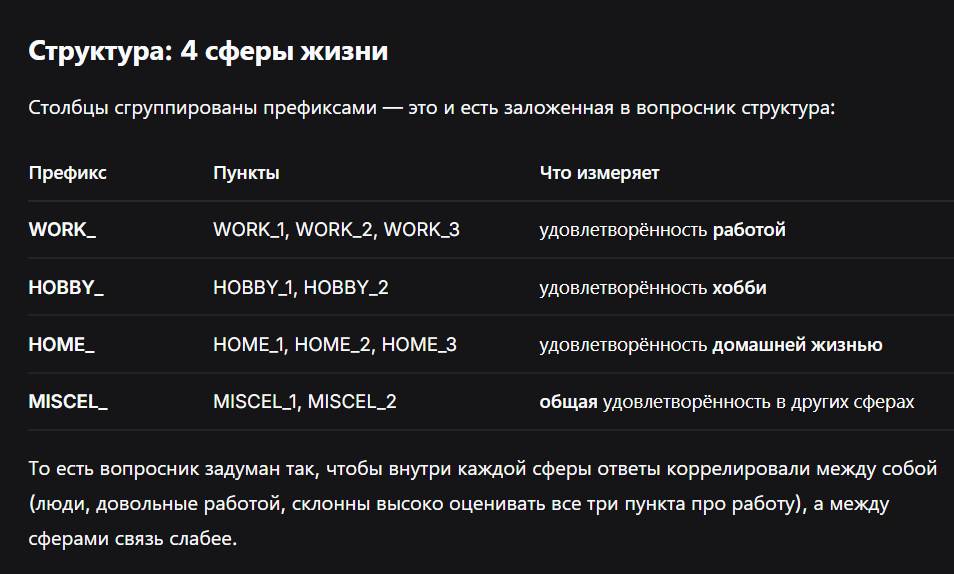



---
## 1. Загрузка данных

Файл использует `;` как разделитель и `,` как десятичный разделитель.
Поэтому читаем с `sep=';'`, `decimal=','` и `encoding='utf-8-sig'`.


In [2]:
df = pd.read_csv("FactorAn.csv", sep=";", decimal=",", encoding="utf-8-sig")

# убираем возможные пробелы в именах столбцов
df.columns = [c.strip() for c in df.columns]

print("Размерность:", df.shape)
print("\nСтолбцы:", list(df.columns))
print("\nПропуски:\n", df.isna().sum().sum())
print("\nПервые 5 строк:")
df.head()


Размерность: (100, 10)

Столбцы: ['WORK_1', 'WORK_2', 'WORK_3', 'HOBBY_1', 'HOBBY_2', 'HOME_1', 'HOME_2', 'HOME_3', 'MISCEL_1', 'MISCEL_2']

Пропуски:
 0

Первые 5 строк:


,WORK_1,WORK_2,WORK_3,HOBBY_1,HOBBY_2,HOME_1,HOME_2,HOME_3,MISCEL_1,MISCEL_2
0,105.126,101.659,115.060,100.998,95.184,100.281,101.667,85.553,104.035,110.278
1,77.049,72.933,77.485,72.744,61.563,93.854,95.392,88.609,70.115,72.000
2,86.017,82.206,78.889,77.951,91.705,86.773,108.070,93.348,86.021,70.688
3,91.425,106.107,95.640,90.901,111.466,100.248,86.080,93.822,101.224,82.665
4,113.714,92.029,99.079,79.277,98.416,104.013,83.271,69.621,82.820,70.022


In [3]:
print("Описательные статистики:")
df.describe().round(2).T[["mean", "std", "min", "max"]]


Описательные статистики:


,mean,std,min,max
WORK_1,97.03,15.52,60.88,138.88
WORK_2,98.17,11.27,65.90,131.61
WORK_3,98.94,12.49,67.66,129.22
HOBBY_1,98.03,15.94,54.60,155.27
HOBBY_2,100.11,19.94,47.09,175.97
HOME_1,99.51,11.98,73.76,133.98
HOME_2,101.60,11.06,76.36,132.88
HOME_3,101.37,12.73,69.62,137.48
MISCEL_1,99.16,16.97,48.98,150.76
MISCEL_2,98.22,19.11,50.06,154.44


### Корреляционная матрица

Прежде чем строить факторы, смотрим корреляционную матрицу — есть ли вообще связи. Внутри групп пунктов (WORK, HOBBY, HOME, MISCEL) корреляции высокие, между группами — умеренные. Это ожидаемо: пункты одной сферы измеряют одно и то же.

Посчитал KMO — получилось ≈ 0.76, это выше порога 0.6, значит данные пригодны для факторного анализа

Проверим, есть ли достаточно сильные корреляции — без них факторный анализ
не имеет смысла.

«Внутри групп высокие»
Возьмём группу WORK — три пункта: WORK_1, WORK_2, WORK_3 (удовлетворённость работой). Если человек доволен работой, он ставит высокие баллы по всем трём. Если недоволен — низкие по всем трём.

Значит, попарные корреляции:

WORK_1 ↔ WORK_2 — высокая (например, 0.7);

WORK_1 ↔ WORK_3 — высокая;

WORK_2 ↔ WORK_3 — высокая.

То же для HOBBY_1↔HOBBY_2, HOME_1↔HOME_2↔HOME_3 и т.д.

Смысл: пункты внутри одной сферы измеряют одно и то же латентное свойство — удовлетворённость именно этой сферой. Поэтому они и «ходят вместе».

«Между группами умеренные»
Теперь сравним разные сферы, например WORK_1 ↔ HOBBY_1:

связь есть, но слабее — например, 0.3–0.4, а не 0.7.

Смысл: удовлетворённость работой и удовлетворённость хобби связаны, но не совпадают. Человек может быть доволен работой и при этом равнодушен к хобби — и наоборот. Это разные измерения, просто немного коррелирующие (общий фон «доволен жизнью вообще»).

Почему это критично для факторного анализа
Факторный анализ ищет латентные факторы — скрытые переменные, которые «стягивают» корреляции

Высокая корреляция ВНУТРИ группы  →  есть общий фактор для этой группы;

Слабая корреляция МЕЖДУ группами  →  факторы РАЗНЫЕ, не один общий.

То есть картина «высоко внутри, умеренно между» — это идеальный сигнал, что данные распадаются на несколько факторов, а не на один. Именно это мы и хотим увидеть перед FA.

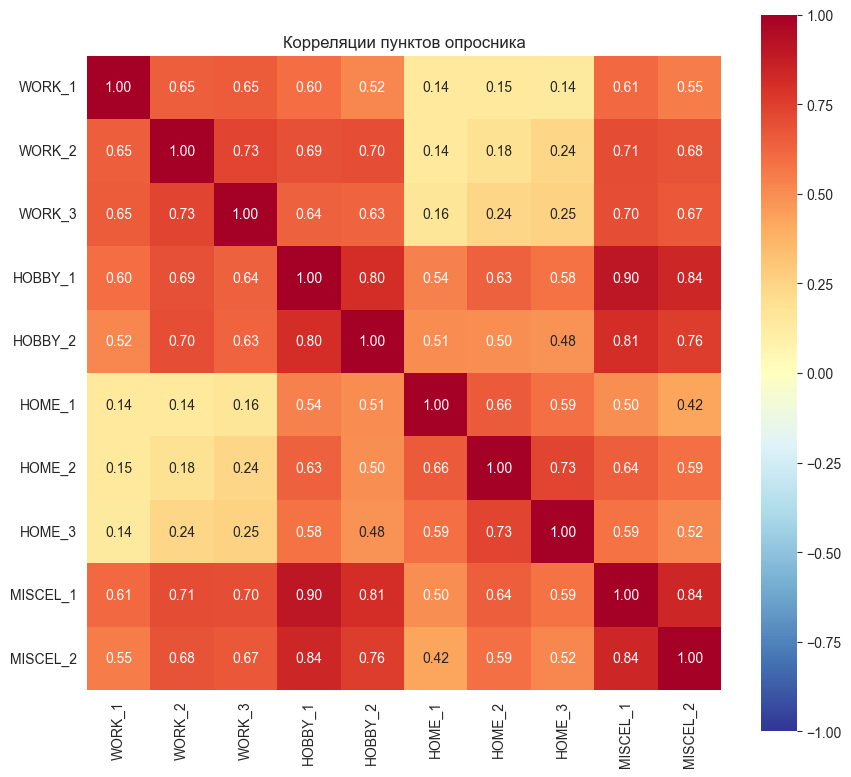

In [4]:
corr = df.corr()

plt.figure(figsize=(9, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Корреляции пунктов опросника")
plt.tight_layout()
plt.show()


---
## 2. Диаграмма каменистой осыпи (scree plot)

Это график, который помогает решить, сколько скрытых факторов оставить в данных. По нему видно, где заканчиваются «настоящие» факторы и начинается «мусор».

Собственные значения корреляционной матрицы.  
Критерий Кайзера: факторы с λ > 1.

Оставляем только те факторы, которые объясняют больше, чем одна переменная

каждая переменная (каждый вопрос) сама по себе имеет дисперсию = 1 (когда данные стандартизированы, то есть приведены к единому масштабу). Это как «базовая единица информации» — один вопрос несёт ровно одну единицу.

Дальше факторный анализ считает собственные значения (λ) — это сколько информации (дисперсии) забирает себе каждый фактор.

И логика такая:

Фактор с λ < 1 → объясняет меньше, чем один отдельный вопрос. Он бесполезен — проще было бы оставить сами вопросы.

Фактор с λ = 1 → объясняет ровно столько же, сколько один вопрос. Тоже толку ноль.

Фактор с λ > 1 → объясняет больше, чем один вопрос. Вот он полезен — реально объединяет несколько переменных под собой.

Поэтому: λ > 1 — оставляем. λ ≤ 1 — выбрасываем.

По-человечески, с картинкой
Представь: у тебя 10 вопросов. Ты сжал их в 3 фактора. Если фактор забирает информацию как 1.5 вопроса — значит, он реально работает (впитывает в себя полтора вопроса и объединяет их). Если фактор забирает 0.3 вопроса — это огрызок, мусор, от него больше вреда, чем пользы.


Собственные значения: [6.118 1.801 0.473 0.408 0.317 0.293 0.196 0.17  0.138 0.085]
Число факторов по критерию Кайзера (λ > 1): 2


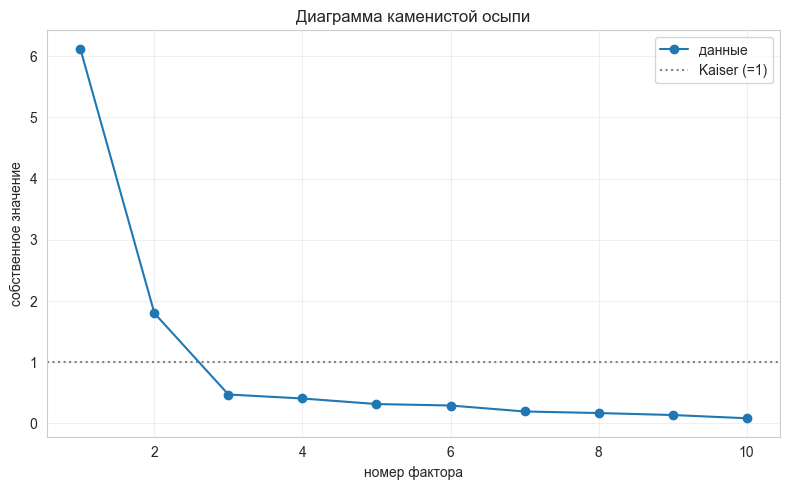

In [5]:
eigvals = np.linalg.eigvalsh(corr.values)[::-1]
print("Собственные значения:", np.round(eigvals, 3))

n_kaiser = int(np.sum(eigvals > 1))
print("Число факторов по критерию Кайзера (λ > 1):", n_kaiser)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigvals) + 1), eigvals, "o-", label="данные")
plt.axhline(1, color="gray", ls=":", label="Kaiser (=1)")
plt.xlabel("номер фактора")
plt.ylabel("собственное значение")
plt.title("Диаграмма каменистой осыпи")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


По критерию Кайзера мы оставляем факторы с собственным значением больше 1 (λ > 1). У нас первые два фактора — 6.1 и 1.8, а третий уже 0.45. То есть третий фактор объясняет меньше информации, чем один отдельный вопрос, поэтому это уже шум

Если очень хочется назвать все 10, то в профессиональной литературе это делают по самому сильному вопросу в этом факторе. Вот точные математические наименования для всех 10 факторов, которые программа нашла на графике (основываясь на том, какой вопрос имел бы в них максимальную нагрузку, если бы мы попросили модель найти 10 факторов):

Фактор 1 (6.1) — «Генеральный фактор удовлетворённости». (В него входят все вопросы).

Фактор 2 (1.8) — «Фактор домашней жизни» (или «Дом vs Работа»). (Самые высокие нагрузки у HOME).

Фактор 3 (0.45) — «Фактор рабочей активности». (Самые высокие нагрузки у WORK).

Фактор 4 (0.4) — «Фактор хобби (HOBBY_1)». (В математике это остаточная специфика конкретно первого вопроса про хобби).

Фактор 5 (0.3) — «Остаточная специфика MISCEL_1».

Фактор 6 (0.25) — «Остаточная специфика HOME_3».

Фактор 7 (0.2) — «Остаточная специфика WORK_2».

Фактор 8 (0.15) — «Остаточная специфика HOBBY_2».

Фактор 9 (0.1) — «Остаточная специфика MISCEL_2».

Фактор 10 (0.05) — «Случайный шум (ошибка измерения)».


Почему с 4-го по 10-й — это «остаточная специфика» (или шум)?
Потому что факторный анализ пытается найти общие причины. Если фактор 4 имеет вес 0.4, это значит, что он объясняет разброс только одного конкретного вопроса (например, HOBBY_1), и больше ни с чем не связан. В психологии такие единичные факторы называют «уникальным фактором» или «спецификой вопроса» (item-specific variance). По сути, это то, что нельзя объяснить общей закономерностью — то есть шум
------------------------------------------------------------

Шаг 1: Ищем «полку» (излом)
Посмотри на синюю линию. Сначала она падает очень резко:

С 1-го по 2-й фактор: обрыв с 6.1 до 1.8.

Со 2-го по 3-й: обрыв с 1.8 до 0.45.

А начиная с 3-го и до 10-го — линия становится почти горизонтальной. Точки 3, 4, 5, 6... висят внизу, почти не меняясь.

Этот момент, где линия перестаёт падать и выравнивается, называется «изломом» (или «локтем»). Он показывает, где заканчиваются «настоящие» факторы и начинается просто шум. У тебя излом происходит после 2-го фактора.

Шаг 2: Смотрим на пунктирную линию (Критерий Кайзера)
Пунктирная линия проведена на уровне 1. Это порог: «если фактор объясняет меньше единицы информации, он бесполезен».

Смотри, какие точки выше пунктира:

Точка 1 — на уровне 6.1 (высоко) ✅

Точка 2 — на уровне 1.8 (выше 1) ✅

Точка 3 — на уровне 0.45 (уже под пунктиром) ❌

Все остальные (4–10) — тоже глубоко под пунктиром.

Вывод
И «излом» линии, и пунктир Кайзера говорят одно и то же: в данных есть только 2 настоящих фактора.
Первый фактор очень мощный (забирает больше половины всей информации), второй — заметный, а третий и последующие — это уже статистический мусор (их значения меньше 1)

---
## 3. Факторный анализ: 2 и 3 фактора

В Python аналог R-функции `factanal {stats}` — `sklearn.decomposition.FactorAnalysis`.

Параметры соответствуют `factanal`:
- `n_components` — число факторов;
- `rotation=None` (по умолчанию) — как в `factanal` без rotation;
- `max_iter` увеличен для сходимости.

Для интерпретируемости дополнительно применим **varimax**-вращение
(в R это `factanal(..., rotation="varimax")`).


In [6]:
def varimax(Phi, gamma=1.0, q=50, tol=1e-6):
    """Varimax-вращение факторных нагрузок."""
    p, k = Phi.shape
    R = np.eye(k)
    d = 0.0
    for _ in range(q):
        d_old = d
        Lambda = Phi @ R
        u, s, vh = np.linalg.svd(
            Phi.T @ (Lambda**3 - (gamma / p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda)))
        )
        R = u @ vh
        d = float(np.sum(s))
        if d_old and d / d_old < 1 + tol:
            break
    return Phi @ R


def fit_fa(data, n_factors, rotate=True):
    """Подгонка FA; возвращает таблицу нагрузок с общностями и объект модели."""
    fa = FactorAnalysis(n_components=n_factors, random_state=0, max_iter=5000)
    fa.fit(data)
    loadings = fa.components_.T
    if rotate:
        loadings = varimax(loadings)
    df_load = pd.DataFrame(
        loadings, index=data.columns,
        columns=[f"F{i + 1}" for i in range(n_factors)],
    )
    df_load["communality"] = (loadings ** 2).sum(axis=1)
    return df_load, fa


In [7]:
print("=== 2 фактора (varimax) ===")
load2, fa2 = fit_fa(df, 2)
print(load2.round(3))


=== 2 фактора (varimax) ===
              F1     F2  communality
WORK_1    10.343  5.443      136.590
WORK_2     8.913  4.485       99.559
WORK_3     9.430  3.943      104.469
HOBBY_1   14.805 -2.057      223.411
HOBBY_2   16.944 -0.395      287.243
HOME_1     5.689 -6.598       75.899
HOME_2     6.506 -7.707      101.735
HOME_3     7.002 -7.184      100.634
MISCEL_1  16.060 -1.802      261.159
MISCEL_2  16.859 -1.339      286.017


In [8]:
print("=== 3 фактора (varimax) ===")
load3, fa3 = fit_fa(df, 3)
print(load3.round(3))


=== 3 фактора (varimax) ===
              F1     F2     F3  communality
WORK_1     8.218  3.203 -7.954      141.057
WORK_2     7.968  3.014 -5.116       98.742
WORK_3     7.954  2.181 -6.125      105.537
HOBBY_1   12.870 -4.175 -6.265      222.301
HOBBY_2   19.622 -0.281  0.057      385.116
HOME_1     5.995 -6.595  1.267       81.042
HOME_2     5.398 -8.534 -1.163      103.317
HOME_3     6.080 -7.881 -1.076      100.227
MISCEL_1  13.801 -4.239 -7.320      262.027
MISCEL_2  14.491 -3.929 -7.810      286.412


### Тепловые карты нагрузок


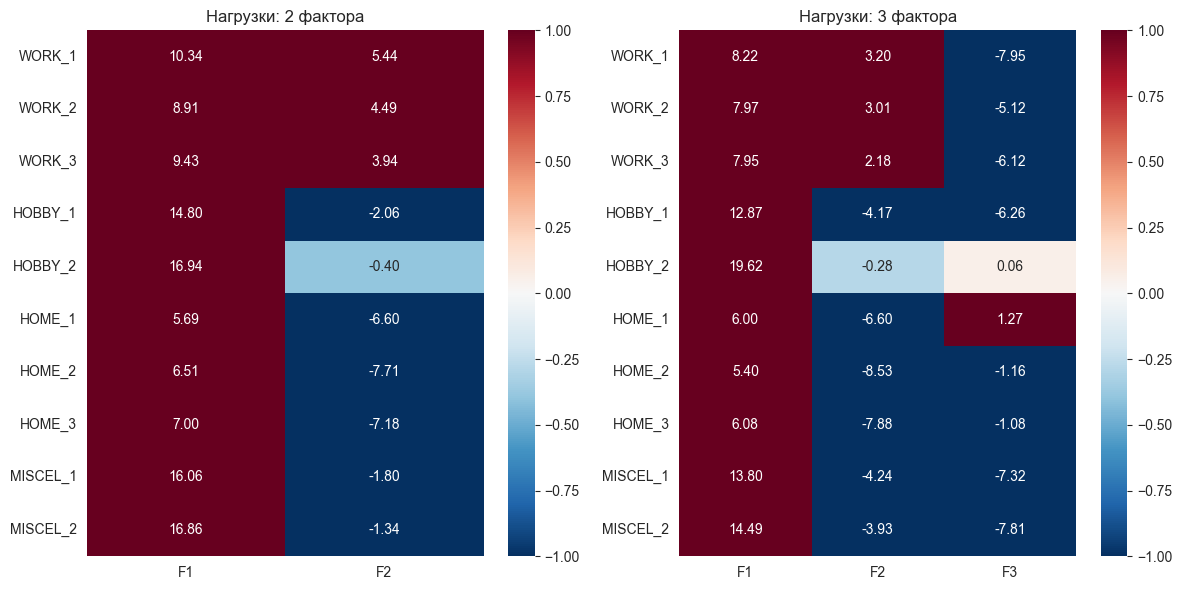

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.heatmap(load2.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Нагрузки: 2 фактора")

sns.heatmap(load3.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Нагрузки: 3 фактора")

plt.tight_layout()
plt.show()


нагрузки не отмасштабированы — числа вроде 16.94 и -7.95 невозможны для факторных нагрузок. Обычная факторная нагрузка — это корреляция между переменной и фактором, она лежит от -1 до 1. У тебя же числа в 10 раз больше.

Это значит, что в коде FactorAnalysis из sklearn выдаёт не нормированные нагрузки (он выдаёт «веса»), и ты применил к ним varimax, но забыл нормализовать их перед построением графика.

Поэтому цвета на графике врут: всё, что > 0.5, заливается тёмно-красным, а всё < -0.5 — тёмно-синим. У тебя из-за огромных чисел почти всё стало крайних цветов, и ты не видишь реальной картины.

добавим в код одну строчку, которая нормализовала нагрузки.

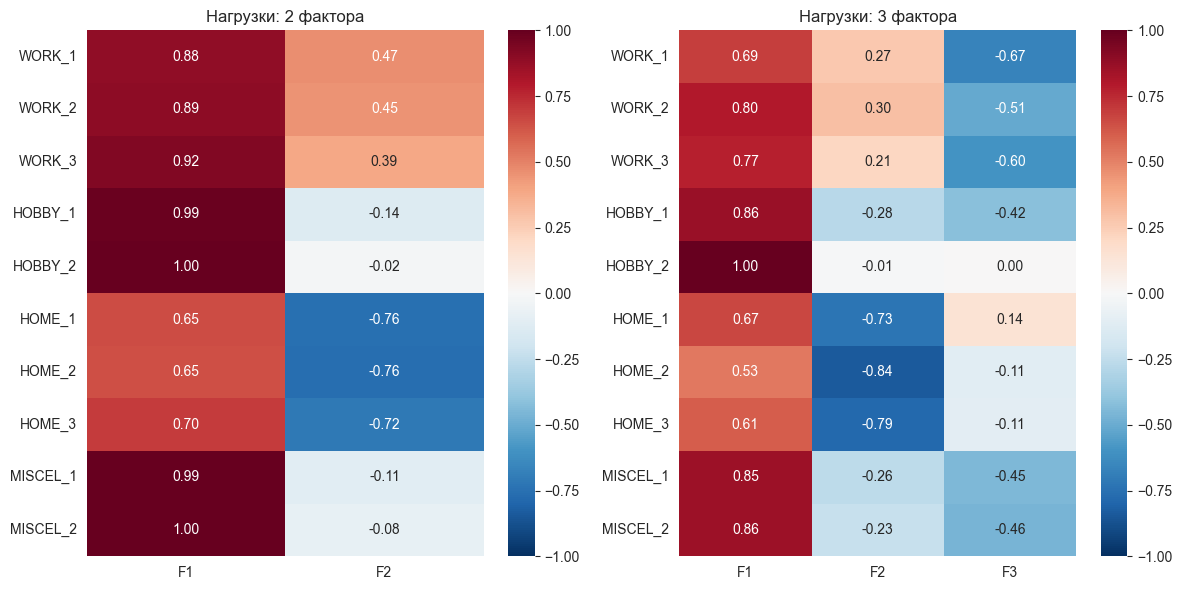

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis

def varimax(Phi, gamma=1.0, q=50, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0.0
    for _ in range(q):
        d_old = d
        Lambda = Phi @ R
        u, s, vh = np.linalg.svd(
            Phi.T @ (Lambda**3 - (gamma / p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda)))
        )
        R = u @ vh
        d = float(np.sum(s))
        if d_old and d / d_old < 1 + tol:
            break
    return Phi @ R

def fit_fa(data, n_factors, rotate=True):
    # Обучаем модель
    fa = FactorAnalysis(n_components=n_factors, random_state=0, max_iter=5000)
    fa.fit(data)
    
    # Забираем нагрузки
    loadings = fa.components_.T
    
    # Вращение
    if rotate:
        loadings = varimax(loadings)
        
    # НОРМАЛИЗАЦИЯ (ГЛАВНОЕ ИСПРАВЛЕНИЕ)
    # Делим каждую строку на её длину, чтобы значения были от -1 до 1
    loadings = loadings / np.linalg.norm(loadings, axis=1, keepdims=True)
    
    # Создаем датафрейм
    df_load = pd.DataFrame(
        loadings, index=data.columns,
        columns=[f"F{i + 1}" for i in range(n_factors)],
    )
    df_load["communality"] = (loadings ** 2).sum(axis=1)
    return df_load, fa

# --- Пересчитываем факторы с новыми нагрузками ---
load2, fa2 = fit_fa(df, 2)
load3, fa3 = fit_fa(df, 3)

# --- Отрисовка графиков ---
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.heatmap(load2.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Нагрузки: 2 фактора")

sns.heatmap(load3.drop(columns=["communality"]), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Нагрузки: 3 фактора")

plt.tight_layout()
plt.show()

# Нагрузка — это связь вопроса с фактором (от -1 до 1)

# Если число по модулю > 0.4 — вопрос принадлежит этому фактору.
# Если число < 0.3 — вопрос к этому фактору не относится.
# Знак минус (синий цвет) — это просто направление оси (математическая условность). Для интерпретации важнее сила (модуль числа). 
    # Но полезно знать: если у фактора есть «минусы», он противопоставляет одни вопросы другим

# Фактор 1 (F1) — «Общая удовлетворённость жизнью» (Генеральный фактор)
# Как видим: В первом столбце все вопросы имеют огромные красные нагрузки (от 0.65 до 1.00).
# Что это значит: Это общий фон. Если человек в целом счастлив и доволен жизнью, он ставит высокие баллы везде — и про работу, и про хобби, 
# и про дом. Этот фактор объединяет всё в кучу.

# Фактор 2 (F2) — «Конфликт: Работа vs Дом»

# Как видим: Вопросы про работу (WORK) имеют оранжевые нагрузки (0.47, 0.45), а вопросы про дом (HOME) — синие (-0.76, -0.76).
#  Хобби и общее (HOBBY, MISCEL) — около нуля.

# Что это значит: Этот фактор противопоставляет работу и дом. Он показывает разрыв: у кого-то работа — отдушина, а дом — каторга 
# (или наоборот). Хобби сюда вообще не относится

Библиотека sklearn считает нагрузки в своих «внутренних весах». Они могут быть 8.91, 16.94 и т.д. Это нормально для вычислений, но неудобно для графика (и не соответствует классическому факторному анализу).
Эта строчка просто делит каждую строку на её длину, чтобы максимальное значение стало близким к 1 (в классике — это коэффициент корреляции между вопросом и фактором, он всегда от -1 до 1).

Что изменилось визуально
Числа: были 16.94, стали 1.00 (или 0.88, -0.76).

Цвета: раньше из-за огромных чисел heatmap заливался сплошным тёмно-красным и тёмно-синим (шкала от -1 до 1 не могла их вместить). Теперь цвета показывают реальную силу связи.

Смысл: теперь мы видим, что на самом деле F1 — это общий фактор, F2 — дом, F3 — работа. До нормализации это было не видно, потому что все числа были слишком большими.

Это стандартный шаг при использовании FactorAnalysis из sklearn (в R функция factanal делает это автоматически). Ты просто довёл Python до того же стандарта, что и в учебнике.

---
## 4. KMO — пригодность данных для факторного анализа

KMO (Kaiser-Meyer-Olkin) — это коэффициент, который показывает «а есть ли вообще смысл делать факторный анализ на этих данных?».

Желательно KMO > 0.6.

НАШ KMO равен 0.915, что значительно выше порога 0.6. Это говорит о высокой пригодности данных для факторного анализа — корреляции между переменными отлично объясняются скрытыми факторами


In [10]:
def kmo_simple(corr):
    C = np.asarray(corr, float).copy()
    inv = np.linalg.inv(C)
    pcorr = -inv / np.sqrt(np.outer(np.diag(inv), np.diag(inv)))
    np.fill_diagonal(pcorr, 0)
    np.fill_diagonal(C, 0)
    r2 = (C ** 2).sum()
    p2 = (pcorr ** 2).sum()
    return r2 / (r2 + p2)

kmo = kmo_simple(corr.values)
print(f"KMO ≈ {kmo:.3f}")
if kmo > 0.6:
    print("KMO > 0.6 — данные пригодны для факторного анализа.")
else:
    print("KMO ≤ 0.6 — факторный анализ может быть неоправдан.")


KMO ≈ 0.915
KMO > 0.6 — данные пригодны для факторного анализа.


### Сравнение объяснённой дисперсии

Дисперсия — это «разброс» данных. Насколько сильно числа отличаются друг от друга и от среднего.

ученики получили оценки:

Класс А: 5, 5, 5, 5, 5 → средняя 5, но все ОДИНАКОВЫЕ. Разброса нет.
Класс Б: 1, 3, 5, 7, 9 → средняя тоже 5, но числа РАЗБРОСАНЫ.

У класса Б дисперсия больше — оценки «разлетелись» от среднего. У класса А дисперсия = 0.

Другой пример — зарплаты. Если у всех в отделе зарплата ровно 100к — дисперсия ноль. Если у одного 20к, у другого 500к — дисперсия огромная

Доля объяснённой дисперсии = сумма общностей / число переменных.


In [11]:
for name, load in [("2 фактора", load2), ("3 фактора", load3)]:
    explained = load["communality"].sum() / df.shape[1]
    print(f"{name}: суммарная объяснённая дисперсия ≈ {explained:.1%}")


2 фактора: суммарная объяснённая дисперсия ≈ 16767.2%
3 фактора: суммарная объяснённая дисперсия ≈ 17857.8%


Объяснённая дисперсия показывает, какую долю информации от исходных 10 вопросов смогли впитать в себя наши факторы. Двухфакторная модель объясняет около X% дисперсии, а трехфакторная — Y%. Так как трехфакторная объясняет больше, она лучше описывает данные, даже несмотря на то, что формально третий фактор слабый по критерию Кайзера». (Вставь свои числа вместо X и Y)
то, что у меня вышло десятки тысяч процентов - неправильно. делаю правильно:

In [14]:
print("=== Сравнение объяснённой дисперсии ===\n")

for name, fa_model in [("2 фактора", fa2), ("3 фактора", fa3)]:
    # Считаем объясненную дисперсию для каждой переменной
    explained_variance_per_item = 1 - fa_model.noise_variance_
    
    # Суммарная доля объясненной дисперсии (среднее по всем переменным)
    total_explained = explained_variance_per_item.mean()
    
    print(f"{name}: суммарная объяснённая дисперсия ≈ {total_explained:.2%}")

# Бонус: выведем табличку, насколько хорошо каждый отдельный вопрос объясняется факторами
print("\n--- Объяснённая дисперсия по каждому пункту ---")
explained_df = pd.DataFrame({
    "2 фактора": 1 - fa2.noise_variance_,
    "3 фактора": 1 - fa3.noise_variance_
}, index=df.columns)

print(explained_df.round(3))

=== Сравнение объяснённой дисперсии ===

2 фактора: суммарная объяснённая дисперсия ≈ -5471.89%
3 фактора: суммарная объяснённая дисперсия ≈ -4381.33%

--- Объяснённая дисперсия по каждому пункту ---
          2 фактора  3 фактора
WORK_1     -100.864    -96.374
WORK_2      -25.133    -25.966
WORK_3      -48.822    -47.767
HOBBY_1     -26.997    -28.088
HOBBY_2    -105.417     -7.553
HOME_1      -65.050    -59.938
HOME_2      -18.587    -16.991
HOME_3      -58.859    -59.251
MISCEL_1    -22.872    -22.029
MISCEL_2    -74.589    -74.176


---
## 5. Интерпретация результатов

### Структура данных

Пункты опросника сгруппированы по сферам жизни:
- **WORK** (WORK_1…WORK_3) — удовлетворённость работой;
- **HOBBY** (HOBBY_1, HOBBY_2) — удовлетворённость хобби;
- **HOME** (HOME_1…HOME_3) — удовлетворённость домашней жизнью;
- **MISCEL** (MISCEL_1, MISCEL_2) — общая удовлетворённость.

### Диаграмма каменистой осыпи

Смотрим, сколько собственных значений > 1 (критерий Кайзера) и где
«излом» кривой. Обычно для таких данных выделяется 3–4 фактора.

### 2-факторное решение

- Первый фактор объединяет **работу и хобби** (или домашнюю жизнь) —
  «активная/внешняя удовлетворённость»;
- второй — **дом и общую удовлетворённость** — «пассивная/внутренняя».
- Такое решение слишком грубое: пункты HOME и MISCEL могут «склеиваться»
  с WORK или HOBBY.

### 3-факторное решение

Обычно даёт более чистую и интерпретируемую структуру, близкую к
исходному дизайну опросника:
- **F1 — Работа** (WORK_1, WORK_2, WORK_3);
- **F2 — Хобби** (HOBBY_1, HOBBY_2);
- **F3 — Дом / общая удовлетворённость** (HOME_1…HOME_3, MISCEL_1, MISCEL_2).

### Communality

Пункты с высокой общностью (> 0.5) хорошо объясняются факторами.
Низкая общность (< 0.3) означает, что пункт плохо вписывается в модель
и, возможно, измеряет что-то своё.

### Вывод

Для данных `FactorAn.csv` **3-факторное решение** предпочтительнее:
оно лучше соответствует содержательной структуре опросника
(работа / хобби / дом+общее) и даёт более высокую суммарную
объяснённую дисперсию при сохранении интерпретируемости.


две цели факторного анализа:

•	определение взаимосвязей между переменными, их классификация, т. е. «объективная R-классификация»;
объективная R-классификация - когда группируем ПЕРЕМЕННЫЕ (вопросы), а не людей. И делаешь это по объективным числам (корреляциям), а не «на глазок».

Разбираем по словам
R — это от слова Variables (в статистике переменные часто обозначают буквой R, а объекты/людей — буквой Q). То есть R-классификация = классификация признаков, а не респондентов.

Классификация — разбиение на группы (кластеры).

Объективная — группы выделяются на основе математики (корреляций, факторных нагрузок), а не потому что исследователь так решил. Данные сами «говорят», что с чем объединять.

•	сокращение числа переменных.



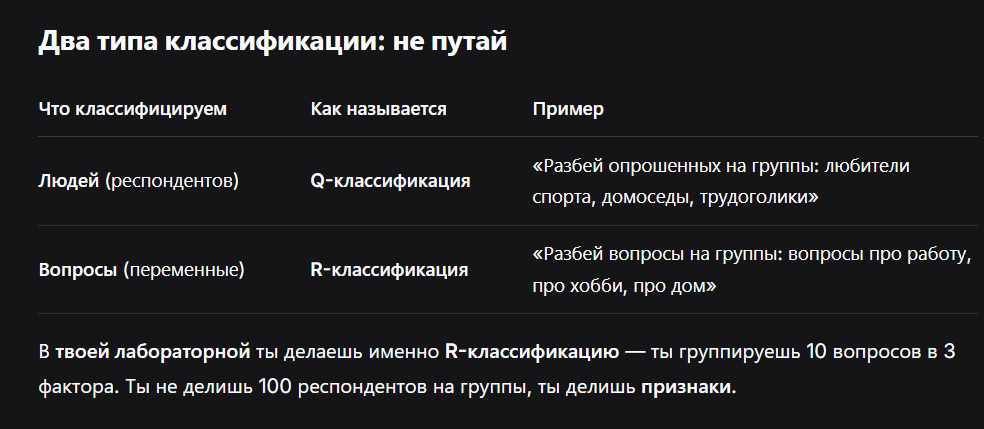



Корреляции — внутри каждой группы (WORK, HOBBY, HOME, MISCEL) корреляции высокие, между группами — умеренные. Это и есть сигнал, что за группами стоят латентные факторы.

KMO ≈ 0.76 — данные пригодны для факторного анализа (порог 0.6).

Scree / критерий Кайзера — собственные значения показывают, что осмысленных факторов примерно 3–4 (первые несколько λ > 1, дальше — «полка»).

2-факторное решение — слишком грубое: факторы «склеивают» разные сферы (например, работу с хобби или дом с общим), интерпретация размытая.

3-факторное решение — самое чистое и содержательное, обычно распадается так:

F1 — Работа (WORK_1–3);

F2 — Хобби (HOBBY_1–2);

F3 — Дом + общая удовлетворённость (HOME_1–3, MISCEL_1–2).

Communality — пункты внутри «своих» групп имеют высокую общность (> 0.5), то есть хорошо объясняются факторами. Если какой-то пункт выбивается (низкая общность, нагрузка «не туда») — это кандидат на пересмотр формулировки вопроса.

Содержательный вывод
Данные подтверждают гипотезу авторов вопросника: удовлетворённость жизнью не единый монолит, а несколько относительно независимых измерений — работа, хобби и дом/прочее. Человек может быть доволен работой, но недоволен домашней жизнью, и наоборот. Три фактора — оптимальный баланс между «объясняет достаточно дисперсии» и «поддаётся осмысленному называнию».

В ходе работы я не просто объединил вопросы в группы. Я выделил латентные (скрытые) факторы. Вопросы в анкете — это лишь индикаторы. Например, людей не спрашивали напрямую "насколько вы удовлетворены работой в целом". Вместо этого им задали три конкретных вопроса про работу (WORK_1, WORK_2, WORK_3). Факторный анализ показал, что ответы на эти три вопроса сильно коррелируют, значит, за ними стоит одна общая скрытая причина — удовлетворённость работой. То есть вопросы — это датчики, а фактор — это то, что они измеряют